# Part 2: Demobilization vs. Persuasion Decomposition

Decomposes the 2020→2024 Democratic vote change into two components at the county level:

**ΔDem votes = Turnout component + Share component**

- **Turnout component** = `dem_share_2020 × (total_2024 − total_2020)` — votes gained/lost purely from overall turnout change, holding Harris at Biden's share
- **Share component** = `(dem_share_2024 − dem_share_2020) × total_2024` — votes gained/lost from shifts in the Democratic share of the electorate (persuasion + differential mobilization)

The share component cannot cleanly separate persuasion from differential demobilization at county level — that requires individual-level data. But counties where turnout held flat but share collapsed point to persuasion; counties where share held but turnout fell point to demobilization.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

DATA_DIR    = Path('../data/raw/mit_election_lab')
PROC_DIR    = Path('../data/processed')
FIGURES_DIR = Path('../outputs/figures')
TABLES_DIR  = Path('../outputs/tables')

for d in [PROC_DIR, FIGURES_DIR, TABLES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

## 1. Load and reshape county returns

In [2]:
raw = pd.read_csv(DATA_DIR / 'county_returns.csv')
print(f"Loaded {len(raw):,} rows | years: {sorted(raw['year'].unique())} | states: {raw['state'].nunique()}")

# Build wide format: one row per county, columns suffixed by year
cols = ['dem_votes', 'rep_votes', 'total_votes', 'dem_share', 'dem_margin']
frames = {}
for yr in [2016, 2020, 2024]:
    sub = raw[raw['year'] == yr][['state', 'county_fips'] + cols].copy()
    sub.columns = ['state', 'county_fips'] + [f'{c}_{yr}' for c in cols]
    frames[yr] = sub

# Inner join: only counties present in all three years
cty = frames[2020].merge(frames[2024], on=['state', 'county_fips'])
cty = cty.merge(frames[2016], on=['state', 'county_fips'])
print(f"Counties with 2016 + 2020 + 2024 data: {len(cty):,}")
cty.head(3)

Loaded 20,873 rows | years: [2000, 2004, 2008, 2012, 2016, 2020, 2024] | states: 51
Counties with 2016 + 2020 + 2024 data: 2,029


,state,county_fips,dem_votes_2020,rep_votes_2020,total_votes_2020,dem_share_2020,dem_margin_2020,dem_votes_2024,rep_votes_2024,total_votes_2024,dem_share_2024,dem_margin_2024,dem_votes_2016,rep_votes_2016,total_votes_2016,dem_share_2016,dem_margin_2016
0,ALABAMA,1001.0,7503,19838,27770,0.270184,-0.444184,7439,20484,28281,0.263039,-0.461264,5936,18172,24973,0.237697,-0.489969
1,ALABAMA,1003.0,24578,83544,109679,0.224090,-0.537623,24934,95798,122249,0.203961,-0.579669,18458,72883,95215,0.193856,-0.571601
2,ALABAMA,1005.0,4816,5622,10518,0.457882,-0.076631,4158,5606,9855,0.421918,-0.146930,4871,5454,10469,0.465278,-0.055688


## 2. National-level decomposition: 2020 → 2024

In [3]:
def national_decomp(df_raw, yr_a, yr_b):
    """Kitagawa-Blinder decomposition between two election years at national level."""
    a = df_raw[df_raw['year'] == yr_a][['dem_votes', 'rep_votes', 'total_votes']].sum()
    b = df_raw[df_raw['year'] == yr_b][['dem_votes', 'rep_votes', 'total_votes']].sum()

    share_a = a['dem_votes'] / a['total_votes']
    share_b = b['dem_votes'] / b['total_votes']

    delta       = b['dem_votes'] - a['dem_votes']
    turnout_c   = share_a * (b['total_votes'] - a['total_votes'])
    share_c     = (share_b - share_a) * b['total_votes']

    return dict(
        dem_votes_a=a['dem_votes'], dem_votes_b=b['dem_votes'],
        total_votes_a=a['total_votes'], total_votes_b=b['total_votes'],
        dem_share_a=share_a, dem_share_b=share_b,
        delta_dem=delta, turnout_component=turnout_c, share_component=share_c,
    )

r2024 = national_decomp(raw, 2020, 2024)
r2020 = national_decomp(raw, 2016, 2020)

def print_decomp(r, yr_a, yr_b):
    print(f"  {yr_a} Dem votes:   {r['dem_votes_a']:>13,.0f}  ({r['dem_share_a']:.1%} raw share)")
    print(f"  {yr_b} Dem votes:   {r['dem_votes_b']:>13,.0f}  ({r['dem_share_b']:.1%} raw share)")
    print(f"  Change:           {r['delta_dem']:>+13,.0f}")
    pct_t = r['turnout_component'] / abs(r['delta_dem'])
    pct_s = r['share_component']   / abs(r['delta_dem'])
    print(f"    Turnout component:  {r['turnout_component']:>+13,.0f}  ({pct_t:+.0%} of change)")
    print(f"    Share component:    {r['share_component']:>+13,.0f}  ({pct_s:+.0%} of change)")

print("=" * 60)
print("2020 → 2024")
print("=" * 60)
print_decomp(r2024, 2020, 2024)
print()
print("=" * 60)
print("2016 → 2020  (comparison baseline)")
print("=" * 60)
print_decomp(r2020, 2016, 2020)

2020 → 2024
  2020 Dem votes:      66,194,500  (52.0% raw share)
  2024 Dem votes:      66,955,961  (48.5% raw share)
  Change:                +761,461
    Turnout component:     +5,592,669  (+734% of change)
    Share component:       -4,831,208  (-634% of change)

2016 → 2020  (comparison baseline)
  2016 Dem votes:      65,844,241  (48.2% raw share)
  2020 Dem votes:      66,194,500  (52.0% raw share)
  Change:                +350,259
    Turnout component:     -4,386,881  (-1252% of change)
    Share component:       +4,737,140  (+1352% of change)


## 3. County-level decomposition

In [4]:
# 2020 → 2024 decomposition at county level
cty['delta_dem']        = cty['dem_votes_2024'] - cty['dem_votes_2020']
cty['turnout_component']= cty['dem_share_2020'] * (cty['total_votes_2024'] - cty['total_votes_2020'])
cty['share_component']  = (cty['dem_share_2024'] - cty['dem_share_2020']) * cty['total_votes_2024']

# Swing in margin points (fraction → pp)
cty['swing_2024'] = (cty['dem_margin_2024'] - cty['dem_margin_2020']) * 100
cty['swing_2020'] = (cty['dem_margin_2020'] - cty['dem_margin_2016']) * 100

wt = cty['total_votes_2020']
print(f"Counties shifted R in 2024:      {(cty['swing_2024'] < 0).sum():>5} / {len(cty)}")
print(f"Counties shifted R in 2020:      {(cty['swing_2020'] < 0).sum():>5} / {len(cty)}  (comparison)")
print(f"Median county swing 2020→2024:   {cty['swing_2024'].median():>+.2f} pp")
print(f"Turnout-wtd mean swing 2020→2024:{(cty['swing_2024']*wt).sum()/wt.sum():>+.2f} pp")
print(f"Median county swing 2016→2020:   {cty['swing_2020'].median():>+.2f} pp  (comparison)")

Counties shifted R in 2024:       1826 / 2029
Counties shifted R in 2020:       1010 / 2029  (comparison)
Median county swing 2020→2024:   -3.14 pp
Turnout-wtd mean swing 2020→2024:-5.77 pp
Median county swing 2016→2020:   +0.02 pp  (comparison)


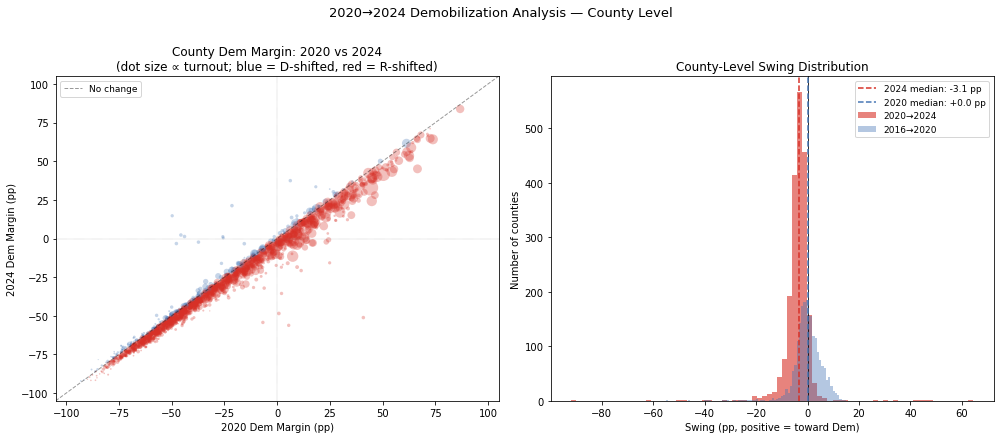

Saved: outputs/figures/demobilization_county.png


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- Left: 2020 vs 2024 dem margin (county scatter) ---
ax = axes[0]
size = np.sqrt(cty['total_votes_2020'].clip(100)) * 0.12
c = ['#4575b4' if s >= 0 else '#d73027' for s in cty['swing_2024']]
ax.scatter(cty['dem_margin_2020'] * 100, cty['dem_margin_2024'] * 100,
           c=c, s=size, alpha=0.3, linewidths=0)
lim = 105
ax.plot([-lim, lim], [-lim, lim], 'k--', alpha=0.4, lw=1, label='No change')
ax.axhline(0, color='gray', lw=0.4, ls=':')
ax.axvline(0, color='gray', lw=0.4, ls=':')
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_xlabel('2020 Dem Margin (pp)')
ax.set_ylabel('2024 Dem Margin (pp)')
ax.set_title('County Dem Margin: 2020 vs 2024\n(dot size ∝ turnout; blue = D-shifted, red = R-shifted)')
ax.legend(fontsize=9)

# --- Right: swing distribution ---
ax = axes[1]
ax.hist(cty['swing_2024'], bins=80, color='#d73027', alpha=0.6, label='2020→2024')
ax.hist(cty['swing_2020'], bins=80, color='#4575b4', alpha=0.4, label='2016→2020')
ax.axvline(0, color='black', lw=0.8)
ax.axvline(cty['swing_2024'].median(), color='#d73027', lw=1.5, ls='--',
           label=f'2024 median: {cty["swing_2024"].median():+.1f} pp')
ax.axvline(cty['swing_2020'].median(), color='#4575b4', lw=1.5, ls='--',
           label=f'2020 median: {cty["swing_2020"].median():+.1f} pp')
ax.set_xlabel('Swing (pp, positive = toward Dem)')
ax.set_ylabel('Number of counties')
ax.set_title('County-Level Swing Distribution')
ax.legend(fontsize=9)

plt.suptitle('2020→2024 Demobilization Analysis — County Level', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'demobilization_county.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: outputs/figures/demobilization_county.png")

## 4. Decomposition by county type: demobilization vs. persuasion signal

Counties are classified by which component dominates their Democratic vote loss:
- **Demobilization-dominant**: turnout fell AND it explains >60% of the Dem vote loss
- **Persuasion-dominant**: share fell AND it explains >60% of the Dem vote loss
- **Mixed / gained**

In [6]:
def classify(row):
    if row['delta_dem'] >= 0:
        return 'Dem gained'
    total = abs(row['delta_dem'])
    t_share = row['turnout_component'] / total
    s_share = row['share_component']   / total
    # Both components pulling in same direction (both negative)
    if row['turnout_component'] <= 0 and row['share_component'] <= 0:
        if t_share <= -0.6:
            return 'Demobilization-dominant'
        if s_share <= -0.6:
            return 'Persuasion-dominant'
        return 'Mixed (both components)'
    return 'Offsetting components'

cty['type'] = cty.apply(classify, axis=1)

# Weight by 2020 Dem votes lost
lost = cty[cty['delta_dem'] < 0].copy()
summary = lost.groupby('type').agg(
    counties=('county_fips', 'count'),
    dem_votes_lost=('delta_dem', 'sum'),
    turnout_c=('turnout_component', 'sum'),
    share_c=('share_component', 'sum'),
).reset_index()
summary['pct_of_total_loss'] = summary['dem_votes_lost'] / lost['delta_dem'].sum() * 100
print(summary.to_string(index=False))

                   type  counties  dem_votes_lost     turnout_c        share_c  pct_of_total_loss
Demobilization-dominant       302        -2643015 -1.805273e+06 -837741.898366          44.314839
Mixed (both components)       308        -1722173 -8.546153e+05 -867557.674113          28.875288
  Offsetting components       563         -346732  1.633088e+05 -510040.848411           5.813578
    Persuasion-dominant       491        -1252256 -3.330367e+05 -919219.293702          20.996295


## 5. State-level decomposition

In [7]:
def state_decomp(df_raw, yr_a, yr_b):
    a = df_raw[df_raw['year'] == yr_a].groupby('state')[['dem_votes','rep_votes','total_votes']].sum()
    b = df_raw[df_raw['year'] == yr_b].groupby('state')[['dem_votes','rep_votes','total_votes']].sum()
    s = a.join(b, lsuffix=f'_{yr_a}', rsuffix=f'_{yr_b}')
    s[f'dem_share_{yr_a}'] = s[f'dem_votes_{yr_a}'] / s[f'total_votes_{yr_a}']
    s[f'dem_share_{yr_b}'] = s[f'dem_votes_{yr_b}'] / s[f'total_votes_{yr_b}']
    s[f'rep_share_{yr_a}'] = s[f'rep_votes_{yr_a}'] / s[f'total_votes_{yr_a}']
    s[f'rep_share_{yr_b}'] = s[f'rep_votes_{yr_b}'] / s[f'total_votes_{yr_b}']
    s['margin_a'] = s[f'dem_share_{yr_a}'] - s[f'rep_share_{yr_a}']
    s['margin_b'] = s[f'dem_share_{yr_b}'] - s[f'rep_share_{yr_b}']
    s['swing']    = (s['margin_b'] - s['margin_a']) * 100
    s['delta_dem']         = s[f'dem_votes_{yr_b}'] - s[f'dem_votes_{yr_a}']
    s['turnout_component'] = s[f'dem_share_{yr_a}'] * (s[f'total_votes_{yr_b}'] - s[f'total_votes_{yr_a}'])
    s['share_component']   = (s[f'dem_share_{yr_b}'] - s[f'dem_share_{yr_a}']) * s[f'total_votes_{yr_b}']
    return s.reset_index()

st = state_decomp(raw, 2020, 2024).sort_values('swing')
print(f"States with rightward swing: {(st['swing'] < 0).sum()} / {len(st)}")
print()
print(st[['state', 'swing', 'delta_dem', 'turnout_component', 'share_component']]
      .head(15).to_string(index=False))

States with rightward swing: 34 / 41

        state      swing  delta_dem  turnout_component  share_component
     NEW YORK -10.340011  -611790.0      -2.411086e+05   -370681.440179
   NEW JERSEY -10.028142  -387622.0      -1.586024e+05   -229019.558207
      FLORIDA  -9.741681  -614007.0      -8.313725e+04   -530869.745632
   CALIFORNIA  -9.024871 -1834071.0      -1.039996e+06   -794075.077466
        TEXAS  -8.104711  -423876.0       3.421692e+04   -458092.917518
MASSACHUSETTS  -8.019125  -255684.0      -1.200458e+05   -135638.245532
    TENNESSEE  -6.511024   -87446.0       3.779224e+03    -91225.224232
       HAWAII  -6.361584   -53083.0      -3.681047e+04    -16272.532007
  MISSISSIPPI  -6.343428   -72730.0      -3.520731e+04    -37522.691888
     ILLINOIS  -6.092573  -409052.0      -2.304163e+05   -178635.725940
  CONNECTICUT  -5.569148   -88778.0      -3.842881e+04    -50349.193434
       NEVADA  -5.497671     1883.0       4.001334e+04    -38130.342273
      ALABAMA  -5.011307  

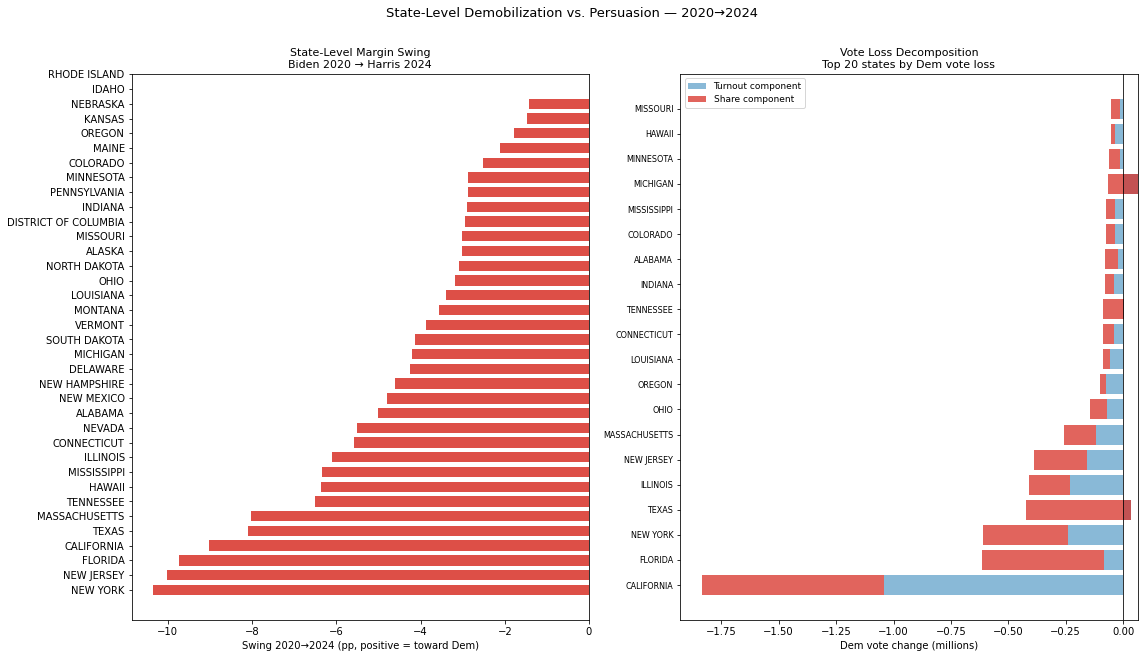

Saved: outputs/figures/demobilization_state.png


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 9))

# --- Left: state swing bar chart ---
ax = axes[0]
colors_bar = ['#4575b4' if s >= 0 else '#d73027' for s in st['swing']]
ax.barh(st['state'], st['swing'], color=colors_bar, alpha=0.85, height=0.7)
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('Swing 2020→2024 (pp, positive = toward Dem)')
ax.set_title('State-Level Margin Swing\nBiden 2020 → Harris 2024', fontsize=11)

# --- Right: stacked decomposition (top 20 by absolute vote loss) ---
ax = axes[1]
top = st.nsmallest(20, 'delta_dem').sort_values('delta_dem')
y = range(len(top))
ax.barh(y, top['turnout_component'] / 1e6, color='#74add1', alpha=0.85, label='Turnout component')
ax.barh(y, top['share_component']   / 1e6, left=top['turnout_component'] / 1e6,
        color='#d73027', alpha=0.75, label='Share component')
ax.set_yticks(list(y))
ax.set_yticklabels(top['state'], fontsize=8)
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('Dem vote change (millions)')
ax.set_title('Vote Loss Decomposition\nTop 20 states by Dem vote loss', fontsize=11)
ax.legend(fontsize=9)

plt.suptitle('State-Level Demobilization vs. Persuasion — 2020→2024', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'demobilization_state.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: outputs/figures/demobilization_state.png")

## 6. Save outputs

In [9]:
# County decomposition → processed (feeds notebook 04)
county_out_cols = [
    'state', 'county_fips',
    'dem_votes_2016', 'dem_votes_2020', 'dem_votes_2024',
    'total_votes_2016', 'total_votes_2020', 'total_votes_2024',
    'dem_share_2016', 'dem_share_2020', 'dem_share_2024',
    'dem_margin_2016', 'dem_margin_2020', 'dem_margin_2024',
    'delta_dem', 'turnout_component', 'share_component',
    'swing_2024', 'swing_2020', 'type',
]
cty[county_out_cols].to_csv(PROC_DIR / 'county_decomposition.csv', index=False)

# State decomposition → tables
st.to_csv(TABLES_DIR / 'state_decomposition_2020_2024.csv', index=False)

print('Saved:')
print('  data/processed/county_decomposition.csv')
print('  outputs/tables/state_decomposition_2020_2024.csv')

Saved:
  data/processed/county_decomposition.csv
  outputs/tables/state_decomposition_2020_2024.csv
